# Experiências de Soft Labels — Exp. 1 a Exp. 6

Resultados da versão ponderada pelo fit. Exp. 6 corresponde à confirmação A/B. Os modelos locais e o modelo global são avaliados separadamente nos holdouts dos próprios clientes. Os resultados são exploratórios; test reservado.

In [ ]:
from pathlib import Path
import sys
root=Path.cwd().resolve()
while not (root/'requirements.txt').exists() and root!=root.parent: root=root.parent
sys.path.insert(0,str(root))

## Exp. 1 — Avaliação separada por dataset

In [1]:
from support.softlabels_overview import render_experiment
render_experiment(1)

Cinco arquiteturas em cada dataset, em federações separadas: dez configurações, seed 2026. Cada resultado desta secção refere-se apenas à sua origem.

PR-AUC local: modelo do cliente no seu próprio holdout. Global: modelo global nos mesmos holdouts. Pesos proporcionais ao fit; não se juntam previsões numa curva única.

Configuração,PR-AUC local,Desvio local,PR-AUC global,Desvio global,Seeds,Cobertura AP
Icentia: CNN+BiLSTM,0.6436,NaN,0.1519,NaN,1,1.0
PhysioNet: CNN+BiLSTM,0.5564,NaN,0.6539,NaN,1,1.0
PhysioNet: ResNet34,0.5371,NaN,0.5558,NaN,1,1.0
Icentia: AE+CNN,0.5097,NaN,0.1436,NaN,1,1.0
PhysioNet: AE+CNN,0.5086,NaN,0.6184,NaN,1,1.0
PhysioNet: MobileNetV2,0.4938,NaN,0.5454,NaN,1,1.0
Icentia: ResNet34,0.4604,NaN,0.1459,NaN,1,1.0
PhysioNet: CNN1D,0.4589,NaN,0.5793,NaN,1,1.0
Icentia: CNN1D,0.3742,NaN,0.1447,NaN,1,1.0
Icentia: MobileNetV2,0.2641,NaN,0.1494,NaN,1,1.0


Três rondas; uma época local por ronda. Amostra smoke fixa.

## Exp. 2 — Combinação dos melhores modelos

In [2]:
from support.softlabels_overview import render_experiment
render_experiment(2)

Cruzamento dos top 3 de cada dataset: nove configurações mistas, seed 2026.

PR-AUC local: modelo do cliente no seu próprio holdout. Global: modelo global nos mesmos holdouts. Pesos proporcionais ao fit; não se juntam previsões numa curva única.

Configuração,PR-AUC local,Desvio local,PR-AUC global,Desvio global,Seeds,Cobertura AP
IC: CNN+BiLSTM / PH: ResNet34,0.6115,NaN,0.5803,NaN,1,1.0
IC: CNN+BiLSTM / PH: MobileNetV2,0.5980,NaN,0.5803,NaN,1,1.0
IC: CNN+BiLSTM / PH: AE+CNN,0.5968,NaN,0.5858,NaN,1,1.0
IC: AE+CNN / PH: ResNet34,0.5202,NaN,0.5416,NaN,1,1.0
IC: AE+CNN / PH: AE+CNN,0.5136,NaN,0.5400,NaN,1,1.0
IC: AE+CNN / PH: MobileNetV2,0.5086,NaN,0.5413,NaN,1,1.0
IC: CNN1D / PH: ResNet34,0.4232,NaN,0.5456,NaN,1,1.0
IC: CNN1D / PH: AE+CNN,0.4160,NaN,0.5445,NaN,1,1.0
IC: CNN1D / PH: MobileNetV2,0.4101,NaN,0.5472,NaN,1,1.0


Três rondas; uma época local por ronda. Amostra smoke fixa.

## Exp. 3 — Exploração alargada de combinações

In [3]:
from support.softlabels_overview import render_experiment
render_experiment(3)

União das cinco arquiteturas atribuída às duas origens: 25 configurações, seeds 2026–2028.

PR-AUC local: modelo do cliente no seu próprio holdout. Global: modelo global nos mesmos holdouts. Pesos proporcionais ao fit; não se juntam previsões numa curva única.

Configuração,PR-AUC local,Desvio local,PR-AUC global,Desvio global,Seeds,Cobertura AP
IC: AE+CNN / PH: MobileNetV2,0.6009,0.0822,0.4786,0.0780,3,1.0
IC: AE+CNN / PH: ResNet34,0.5926,0.0686,0.4743,0.0764,3,1.0
IC: CNN+BiLSTM / PH: MobileNetV2,0.5866,0.0252,0.4774,0.0901,3,1.0
IC: AE+CNN / PH: AE+CNN,0.5835,0.0688,0.4748,0.0719,3,1.0
IC: CNN+BiLSTM / PH: ResNet34,0.5759,0.0320,0.4780,0.0898,3,1.0
IC: CNN+BiLSTM / PH: AE+CNN,0.5686,0.0260,0.4719,0.0987,3,1.0
IC: AE+CNN / PH: CNN+BiLSTM,0.5660,0.0526,0.4731,0.0780,3,1.0
IC: AE+CNN / PH: CNN1D,0.5639,0.0676,0.4724,0.0781,3,1.0
IC: CNN+BiLSTM / PH: CNN+BiLSTM,0.5525,0.0566,0.4707,0.0936,3,1.0
IC: CNN+BiLSTM / PH: CNN1D,0.5495,0.0342,0.4701,0.0974,3,1.0


Três rondas; uma época local por ronda. Amostra smoke fixa.

## Exp. 4 — Escolha da arquitetura por cliente

In [4]:
from support.softlabels_overview import render_experiment
render_experiment(4)

Três regras de escolha: modelo comum, por dataset ou por cliente. Amostra ampliada, seleção interna sem holdout/dev; seeds 2026–2030.

PR-AUC local: modelo do cliente no seu próprio holdout. Global: modelo global nos mesmos holdouts. Pesos proporcionais ao fit; não se juntam previsões numa curva única.

Configuração,PR-AUC local,Desvio local,PR-AUC global,Desvio global,Seeds,Cobertura AP
Modelo por cliente,0.6055,0.1187,0.4660,0.0756,5,1.0
Modelo comum,0.6009,0.1031,0.4641,0.0679,5,1.0
Modelo por dataset,0.5943,0.1099,0.4722,0.0751,5,1.0


Três rondas; uma época local por ronda. Na Exp. 4, a seleção interna dos candidatos usa três épocas e a avaliação final usa fit+seleção.

## Exp. 5 — Melhores combinações e referências homogéneas

In [5]:
from support.softlabels_overview import render_experiment
render_experiment(5)

Análise focada de nove cruzamentos top 3 × top 3 e quatro referências homogéneas adicionais, 13 configurações, seeds 2026–2028. Subconjunto da grelha da Exp. 3, sem validação independente.

PR-AUC local: modelo do cliente no seu próprio holdout. Global: modelo global nos mesmos holdouts. Pesos proporcionais ao fit; não se juntam previsões numa curva única.

Configuração,PR-AUC local,Desvio local,PR-AUC global,Desvio global,Seeds,Cobertura AP
IC: AE+CNN / PH: MobileNetV2,0.6009,0.0822,0.4786,0.0780,3,1.0
IC: AE+CNN / PH: ResNet34,0.5926,0.0686,0.4743,0.0764,3,1.0
IC: CNN+BiLSTM / PH: MobileNetV2,0.5866,0.0252,0.4774,0.0901,3,1.0
IC: AE+CNN / PH: AE+CNN,0.5835,0.0688,0.4748,0.0719,3,1.0
IC: CNN+BiLSTM / PH: ResNet34,0.5759,0.0320,0.4780,0.0898,3,1.0
IC: CNN+BiLSTM / PH: AE+CNN,0.5686,0.0260,0.4719,0.0987,3,1.0
IC: CNN+BiLSTM / PH: CNN+BiLSTM,0.5525,0.0566,0.4707,0.0936,3,1.0
IC: CNN1D / PH: MobileNetV2,0.4785,0.0708,0.4718,0.0804,3,1.0
IC: CNN1D / PH: ResNet34,0.4679,0.0464,0.4723,0.0789,3,1.0
IC: CNN1D / PH: AE+CNN,0.4598,0.0448,0.4661,0.0804,3,1.0


Três rondas; uma época local por ronda. Amostra smoke fixa.

## Exp. 6 — Comparação final A/B

In [6]:
from support.softlabels_overview import render_experiment
render_experiment(6)

A: AE+CNN no Icentia e MobileNetV2 no PhysioNet. B: CNN1D no Icentia e MobileNetV2 no PhysioNet. Amostra ampliada, dez épocas locais por ronda, seeds 2031–2035. Fonte: versão ponderada validada; os artefactos históricos 50/50 não são usados.

PR-AUC local: modelo do cliente no seu próprio holdout. Global: modelo global nos mesmos holdouts. Pesos proporcionais ao fit; não se juntam previsões numa curva única.

Configuração,PR-AUC local,Desvio local,PR-AUC global,Desvio global,Seeds,Cobertura AP
A: AE+CNN / MobileNetV2,0.8048,0.0185,0.438,0.0782,5,1.0
B: CNN1D / MobileNetV2,0.7671,0.0080,0.456,0.0894,5,1.0


**Escolha da Exp. 6: A: AE+CNN / MobileNetV2.** Critério: maior AP local ponderada pelo fit nas cinco seeds. Os resultados históricos com pesos 50/50 não sustentam esta escolha.

## Comparisons — comparação entre experiências

A configuração de cada ponto é escolhida pelo **maior PR-AUC local ponderado, em média entre seeds**. O PR-AUC global apresentado pertence à mesma configuração. A escolha é exploratória e pode beneficiar da seleção entre várias alternativas. Na Exp. 1, escolhe-se uma arquitetura por origem e combina-se a AP por pesos de fit; são duas federações separadas. São apresentadas apenas as Exp. 1–6.

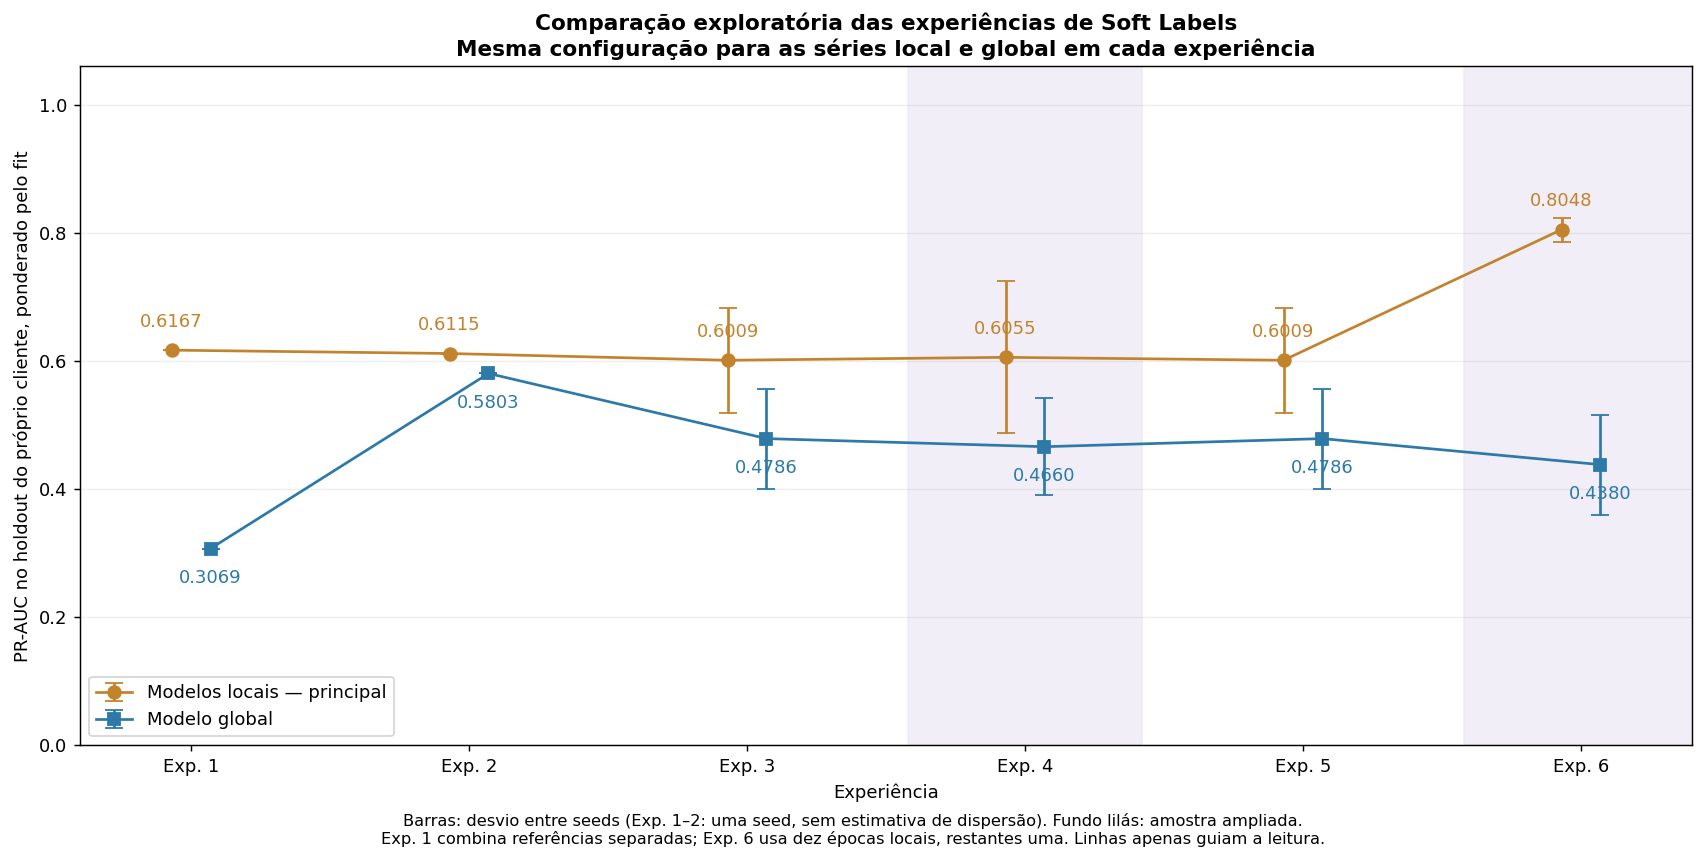

Experiência,Configuração selecionada,PR-AUC local,PR-AUC global,Seeds,Amostra,Épocas locais/ronda,Parcial
1,Icentia: CNN+BiLSTM + PhysioNet: CNN+BiLSTM,0.6167,0.3069,1,smoke,1,False
2,IC: CNN+BiLSTM / PH: ResNet34,0.6115,0.5803,1,smoke,1,False
3,IC: AE+CNN / PH: MobileNetV2,0.6009,0.4786,3,smoke,1,False
4,Modelo por cliente,0.6055,0.4660,5,ampliada,1,False
5,IC: AE+CNN / PH: MobileNetV2,0.6009,0.4786,3,smoke,1,False
6,A: AE+CNN / MobileNetV2,0.8048,0.4380,5,ampliada,10,False


**Maior média local observada neste gráfico: Exp. 6, A: AE+CNN / MobileNetV2 (0.8048).** É uma descrição dos resultados disponíveis, não uma prova de superioridade: as amostras, épocas, seeds e número de configurações exploradas diferem. A Exp. 5 reutiliza o espaço de configurações da Exp. 3. A escolha deve considerar também comunicação e cálculo; test continua reservado.

### Combinação recomendada

**Recomenda-se a configuração A: AE+CNN nos clientes Icentia11k, MobileNetV2 nos clientes PhysioNet 2017 e CNN1D como modelo global, com distilação por probabilidades nas âncoras de referência.** A Exp. 6 selecionou esta combinação pelo PR-AUC local ponderado nas cinco seeds (0.8048); o PR-AUC global da mesma configuração foi 0.4380. A escolha privilegia o desempenho local e é exploratória: não se pode atribuir a melhoria apenas à arquitetura, porque a amostra e o orçamento de treino também diferem das experiências anteriores. A validade das âncoras sintéticas e a generalização do modelo global continuam a exigir avaliação. Os resultados não demonstram maior privacidade ou menor consumo energético; o conjunto de teste permanece reservado.

In [8]:
from support.softlabels_overview import render_comparisons
render_comparisons()